<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_10/Penilitian_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prompt from Teacher:

Saya akan melakukan penelitian tentang klasifikasi dengan algoritma: KNN, Decision Tree, Naive Bayes, Support Vector Machine. Datasetnya ada di /content/bank_data/bank-full.csv. Tambahkan fitur selection menggunakan pearson correlation dan bandingakn model yang tidak pakai fitur selection dengan yang makai. Buatkan program python. dan pastikan digabung jadi 1 cell, JANGAN DIPISAH jadi lebih dari 1 cell, tapi digabung. Pastikan di programnya dapat menampilkan accuracy, presisi, recall, f1-score dalam dataframe baik sebelum adanya fitur selection, maupun adanya fitur selection. Kemudian bisa menampilkan grafik ROC, grafik confusin matrix, grafik heatmap pearson correlation.
A. Tabel yang Direkomendasikan
No.	Nama Tabel	Isi yang Ditampilkan	Prioritas
1	Karakteristik Dataset	Jumlah instance, fitur, kelas, missing value, dan distribusi kelas	Wajib
2	Hasil Analisis Korelasi Fitur	Nilai korelasi masing-masing fitur terhadap target (khusus metode berbasis korelasi)	Opsional
3	Hasil Feature Selection	Fitur yang dipilih, fitur yang dihapus, skor seleksi, dan jumlah fitur setelah seleksi	Wajib
4	Konfigurasi Algoritma Klasifikasi	Algoritma, hyperparameter, metode validasi, dan konfigurasi eksperimen	Wajib
5	Performa Klasifikasi Sebelum Feature Selection	Accuracy, Precision, Recall, dan F1-Score seluruh algoritma	Wajib
6	Performa Klasifikasi Setelah Feature Selection	Accuracy, Precision, Recall, dan F1-Score seluruh algoritma	Wajib
7	Perbandingan Performa Sebelum dan Sesudah Feature Selection	Perubahan Accuracy, Precision, Recall, F1-Score, dan jumlah fitur	Wajib

Tampilkan grafik dan diagram:
B. Grafik dan Diagram yang Direkomendasikan
No.	Grafik/Diagram	Informasi yang Ditampilkan	Tujuan
1	Flowchart Metodologi Penelitian	Dataset → Preprocessing → Feature Selection → Klasifikasi → Evaluasi	Menjelaskan alur penelitian
2	Heatmap Korelasi Fitur	Hubungan antarfitur dan hubungan fitur dengan target	Mengidentifikasi hubungan dan redundansi fitur
3	Bar Chart Jumlah Fitur	Jumlah fitur sebelum dan sesudah seleksi	Menunjukkan efektivitas reduksi fitur
4	Grouped Bar Chart Performa Klasifikasi	Perbandingan Accuracy dan F1-Score sebelum dan sesudah seleksi	Menunjukkan dampak Feature Selection
5	Confusion Matrix	True Positive, True Negative, False Positive, dan False Negative	Menganalisis kesalahan klasifikasi
6	ROC Curve dan AUC	Kemampuan model membedakan kelas pada berbagai threshold	Mengevaluasi kemampuan diskriminasi model



### Mengunduh dan Mengekstrak Dataset Bank Marketing
Kita akan menggunakan perintah shell untuk mengunduh file `.zip` dan mengekstrak serves tersebut di lingkungan Colab.

In [ ]:
# Unduh file zip
!wget https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank_marketing.zip

# Ekstrak file zip utama
!unzip -o bank_marketing.zip -d bank_marketing_extracted

# Lihat isi folder hasil ekstrak
!ls -la bank_marketing_extracted

--2026-11-03 00:28:13--  https://archive.ics.uci.edu/static/public/222/bank+marketing.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘bank_marketing.zip’

bank_marketing.zip      [  <=>               ] 999.85K  3.38MB/s    in 0.3s    

2026-11-03 00:28:13 (3.38 MB/s) - ‘bank_marketing.zip’ saved [1023843]

Archive:  bank_marketing.zip
 extracting: bank_marketing_extracted/bank.zip  
 extracting: bank_marketing_extracted/bank-additional.zip  
total 1012
drwxr-xr-x 2 root root   4096 Nov  3 00:28 .
drwxr-xr-x 1 root root   4096 Nov  3 00:28 ..
-rwx------ 1 root root 444572 May 22  2023 bank-additional.zip
-rwx------ 1 root root 579043 May 22  2023 bank.zip


### Membaca Data
Di dalam folder hasil ekstrak biasanya terdapat file zip tambahan seperti `bank-additional.zip` atau `bank.zip`. Mari kita ekstrak file data tersebut dan membacanya menggunakan pandas.

In [ ]:
import pandas as pd
import zipfile
import os

# Ekstrak bank.zip yang ada di dalam folder tersebut
inner_zip_path = 'bank_marketing_extracted/bank.zip'
if os.path.exists(inner_zip_path):
    with zipfile.ZipFile(inner_zip_path, 'r') as zip_ref:
        zip_ref.extractall('bank_data')

# Membaca data 'bank-full.csv'
df = pd.read_csv('bank_data/bank-full.csv', sep=';')
display(df.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


PENELITIAN KLASIFIKASI DENGAN PEARSON CORRELATION FEATURE SELECTION

Dataset berhasil dimuat!
Dimensi dataset: (45211, 17)

TABEL 1. KARAKTERISTIK DATASET


,Karakteristik,Nilai
0,Jumlah Instance,45211
1,Jumlah Fitur Awal,16
2,Jumlah Kelas,2
3,Missing Value,0
4,Jumlah Data Training,36168
5,Jumlah Data Testing,9043



Distribusi Kelas:


,Kelas,Jumlah,Persentase (%)
0,no,39922,88.3
1,yes,5289,11.7



Jumlah data training: 36168
Jumlah data testing : 9043

Jumlah fitur setelah preprocessing: 51

PERHITUNGAN PEARSON CORRELATION

TABEL 2. HASIL ANALISIS KORELASI FITUR


,Fitur,Pearson Correlation,Absolute Correlation
0,duration,0.39674,0.39674
1,poutcome_success,0.30585,0.30585
2,poutcome_unknown,-0.16332,0.16332
3,contact_unknown,-0.14983,0.14983
4,housing_no,0.13943,0.13943
5,housing_yes,-0.13943,0.13943
6,contact_cellular,0.13264,0.13264
7,month_oct,0.12864,0.12864
8,month_mar,0.12750,0.12750
9,month_sep,0.11725,0.11725



TABEL 3. HASIL FEATURE SELECTION


,Fitur,Pearson Correlation,Absolute Correlation,Status,Ambang Korelasi
0,duration,0.39674,0.39674,Dipilih,0.01
1,poutcome_success,0.30585,0.30585,Dipilih,0.01
2,poutcome_unknown,-0.16332,0.16332,Dipilih,0.01
3,contact_unknown,-0.14983,0.14983,Dipilih,0.01
4,housing_no,0.13943,0.13943,Dipilih,0.01
5,housing_yes,-0.13943,0.13943,Dipilih,0.01
6,contact_cellular,0.13264,0.13264,Dipilih,0.01
7,month_oct,0.12864,0.12864,Dipilih,0.01
8,month_mar,0.12750,0.12750,Dipilih,0.01
9,month_sep,0.11725,0.11725,Dipilih,0.01



Ringkasan Feature Selection:


,Keterangan,Nilai
0,Jumlah fitur sebelum seleksi,51.00
1,Jumlah fitur terpilih,43.00
2,Jumlah fitur dihapus,8.00
3,Persentase reduksi fitur,15.69



Daftar fitur terpilih:
1. duration
2. poutcome_success
3. poutcome_unknown
4. contact_unknown
5. housing_no
6. housing_yes
7. contact_cellular
8. month_oct
9. month_mar
10. month_sep
11. month_may
12. pdays
13. previous
14. job_retired
15. job_student
16. month_dec
17. job_blue-collar
18. campaign
19. loan_no
20. loan_yes
21. month_apr
22. marital_single
23. education_tertiary
24. marital_married
25. balance
26. education_primary
27. month_feb
28. job_management
29. education_secondary
30. month_jul
31. poutcome_other
32. job_services
33. day
34. age
35. default_no
36. default_yes
37. job_unemployed
38. contact_telephone
39. job_entrepreneur
40. job_housemaid
41. month_nov
42. month_jun
43. job_technician

Daftar fitur yang dihapus:
1. job_admin.
2. job_self-employed
3. job_unknown
4. marital_divorced
5. education_unknown
6. month_aug
7. month_jan
8. poutcome_failure

Membuat Flowchart Metodologi Penelitian...


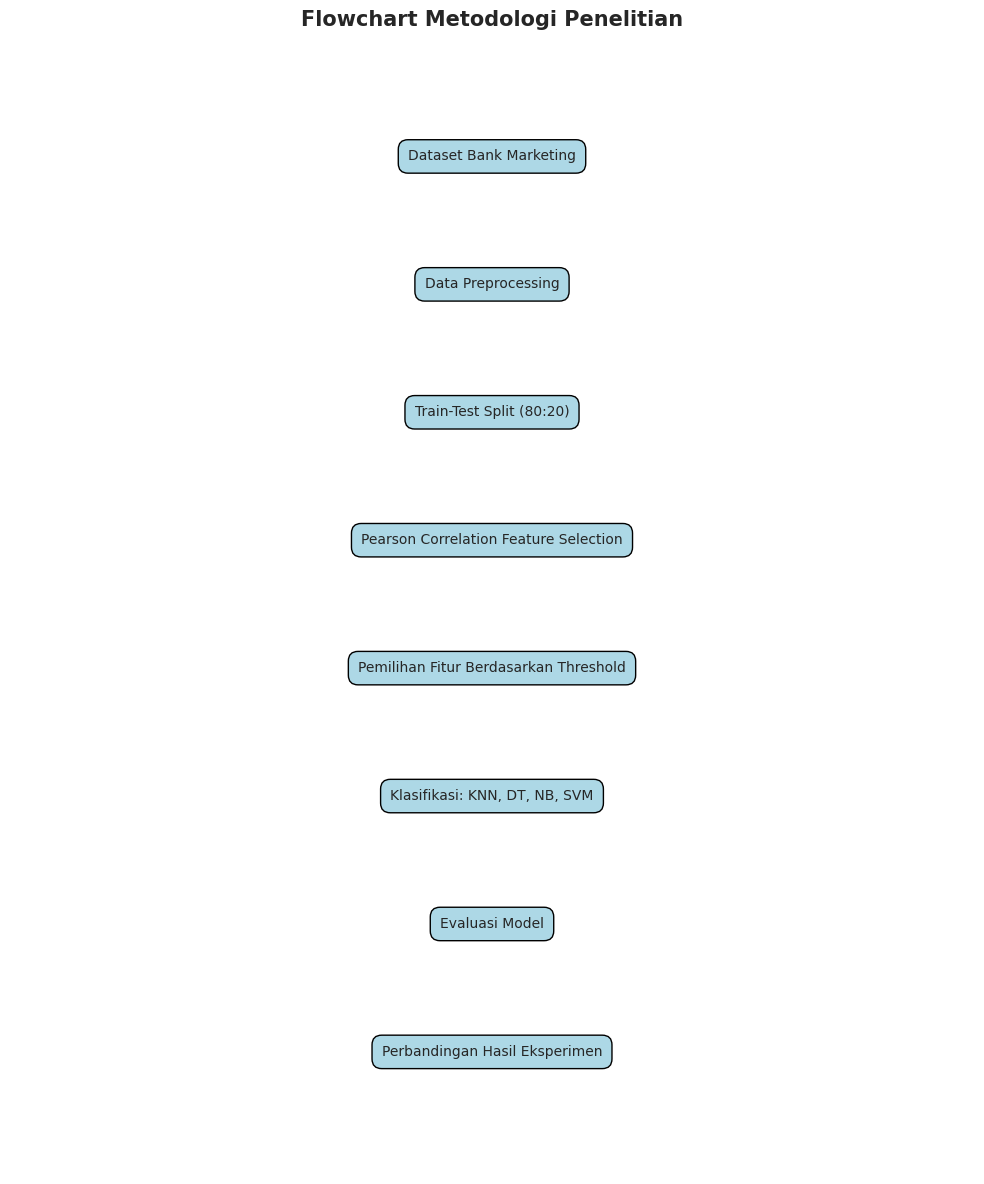


Membuat Heatmap Korelasi...


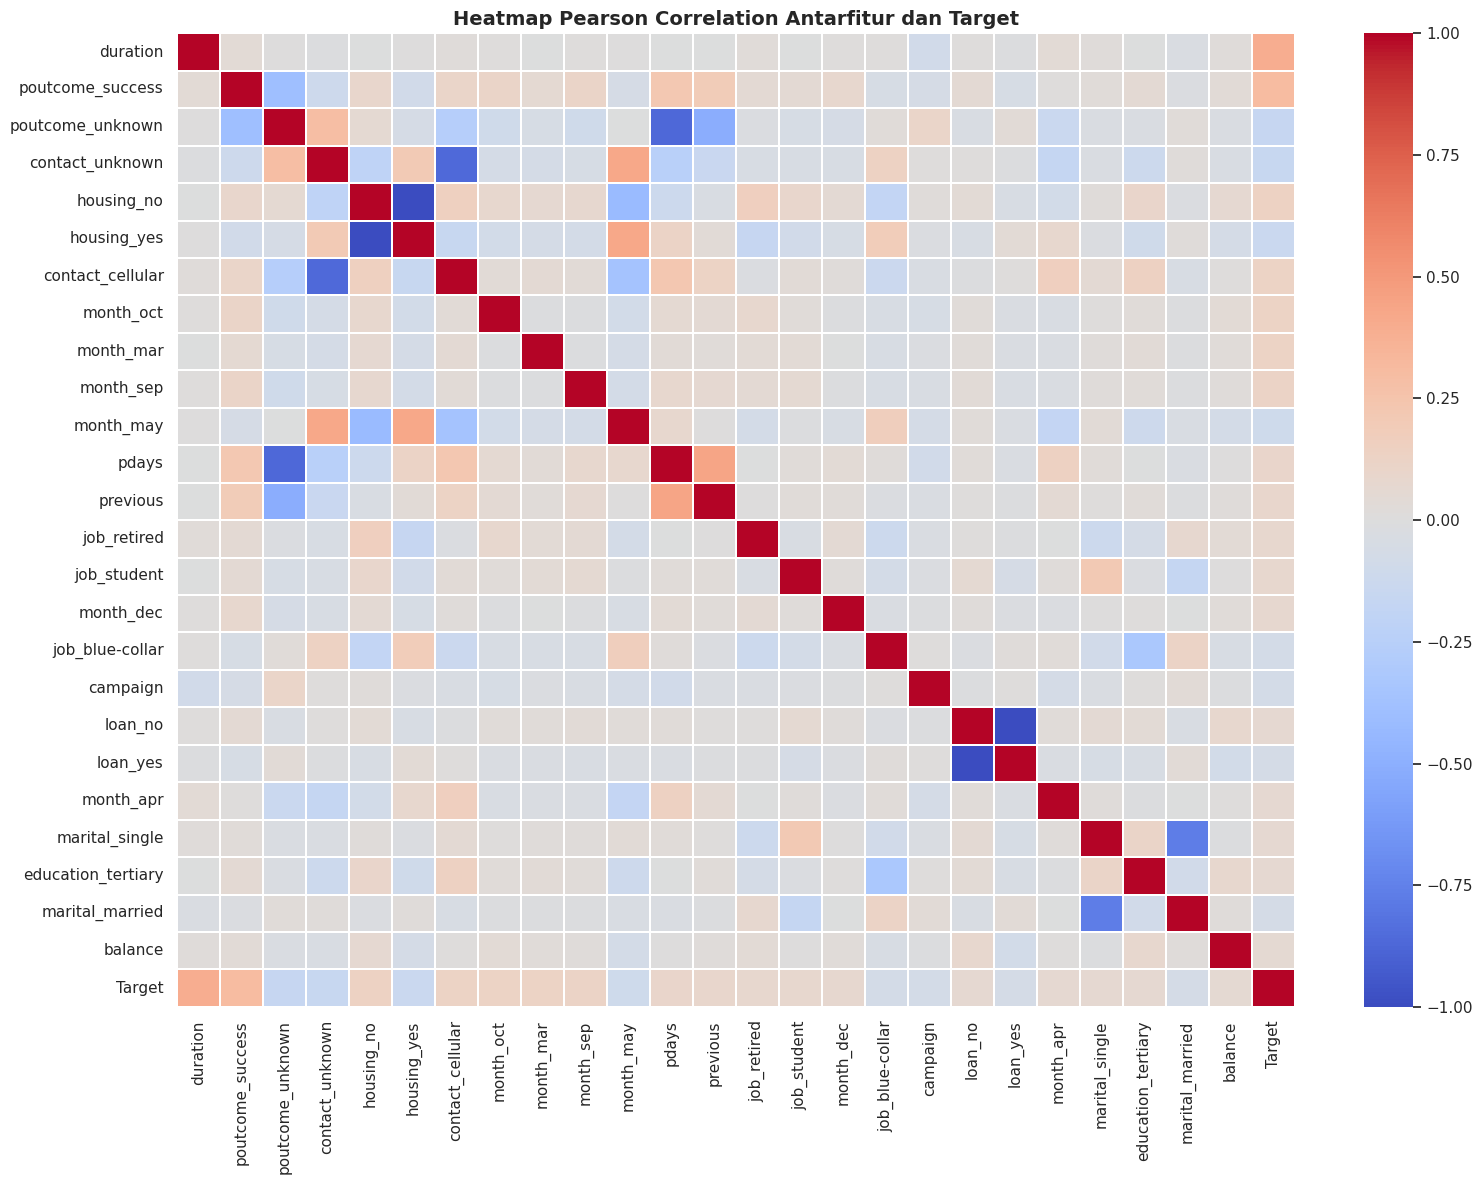


TABEL 4. KONFIGURASI ALGORITMA KLASIFIKASI


,Algoritma,Hyperparameter,Validasi
0,KNN,"n_neighbors=5, weights=uniform",Stratified Train-Test Split 80:20
1,Decision Tree,"criterion=gini, max_depth=None",Stratified Train-Test Split 80:20
2,Naive Bayes,GaussianNB default,Stratified Train-Test Split 80:20
3,SVM,"kernel=rbf, C=1.0, gamma=scale",Stratified Train-Test Split 80:20



PROSES EKSPERIMEN KLASIFIKASI

Menjalankan algoritma: KNN
Tanpa Feature Selection: Accuracy=0.8921, Precision=0.5765, Recall=0.2921, F1=0.3877, AUC=0.8021
Dengan Feature Selection: Accuracy=0.8936, Precision=0.5789, Recall=0.3327, F1=0.4226, AUC=0.8112

Menjalankan algoritma: Decision Tree
Tanpa Feature Selection: Accuracy=0.8746, Precision=0.4649, Recall=0.4754, F1=0.4701, AUC=0.7015
Dengan Feature Selection: Accuracy=0.8729, Precision=0.4590, Recall=0.4820, F1=0.4703, AUC=0.7034

Menjalankan algoritma: Naive Bayes
Tanpa Feature Selection: Accuracy=0.8548, Precision=0.4059, Recall=0.5198, F1=0.4559, AUC=0.8101
Dengan Feature Selection: Accuracy=0.8549, Precision=0.4061, Recall=0.5189, F1=0.4556, AUC=0.8100

Menjalankan algoritma: SVM
Tanpa Feature Selection: Accuracy=0.9047, Precision=0.6914, Recall=0.3346, F1=0.4510, AUC=0.9118
Dengan Feature Selection: Accuracy=0.9029, Precision=0.6852, Recall=0.3147, F1=0.4313, AUC=0.9034

TABEL 5. PERFORMA KLASIFIKASI TANPA FEATURE SELECTION


,Algoritma,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Jumlah Fitur
0,KNN,0.8921,0.5765,0.2921,0.3877,0.8021,51
1,Decision Tree,0.8746,0.4649,0.4754,0.4701,0.7015,51
2,Naive Bayes,0.8548,0.4059,0.5198,0.4559,0.8101,51
3,SVM,0.9047,0.6914,0.3346,0.4510,0.9118,51



TABEL 6. PERFORMA KLASIFIKASI DENGAN FEATURE SELECTION


,Algoritma,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Jumlah Fitur
0,KNN,0.8936,0.5789,0.3327,0.4226,0.8112,43
1,Decision Tree,0.8729,0.4590,0.4820,0.4703,0.7034,43
2,Naive Bayes,0.8549,0.4061,0.5189,0.4556,0.8100,43
3,SVM,0.9029,0.6852,0.3147,0.4313,0.9034,43



TABEL 7. PERBANDINGAN PERFORMA SEBELUM DAN SESUDAH FS


,Algoritma,Accuracy Sebelum,Accuracy Sesudah,Delta Accuracy (pp),Precision Sebelum,Precision Sesudah,Delta Precision (pp),Recall Sebelum,Recall Sesudah,Delta Recall (pp),F1-Score Sebelum,F1-Score Sesudah,Delta F1-Score (pp),ROC-AUC Sebelum,ROC-AUC Sesudah,Delta ROC-AUC (pp),Fitur Sebelum,Fitur Sesudah,Reduksi Fitur (%)
0,KNN,0.8921,0.8936,0.1548,0.5765,0.5789,0.2455,0.2921,0.3327,4.0643,0.3877,0.4226,3.4865,0.8021,0.8112,0.9178,51,43,15.6863
1,Decision Tree,0.8746,0.8729,-0.1659,0.4649,0.4590,-0.5834,0.4754,0.4820,0.6616,0.4701,0.4703,0.0169,0.7015,0.7034,0.1931,51,43,15.6863
2,Naive Bayes,0.8548,0.8549,0.0111,0.4059,0.4061,0.0161,0.5198,0.5189,-0.0945,0.4559,0.4556,-0.0262,0.8101,0.8100,-0.0174,51,43,15.6863
3,SVM,0.9047,0.9029,-0.1769,0.6914,0.6852,-0.6221,0.3346,0.3147,-1.9849,0.4510,0.4313,-1.9608,0.9118,0.9034,-0.8432,51,43,15.6863



Membuat Grafik Jumlah Fitur...


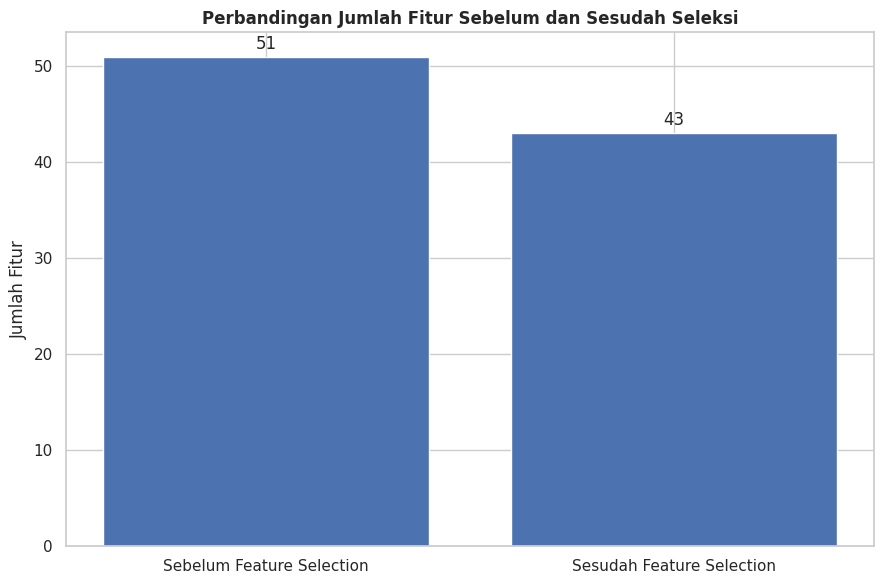


Membuat Grafik Perbandingan Accuracy dan F1-Score...


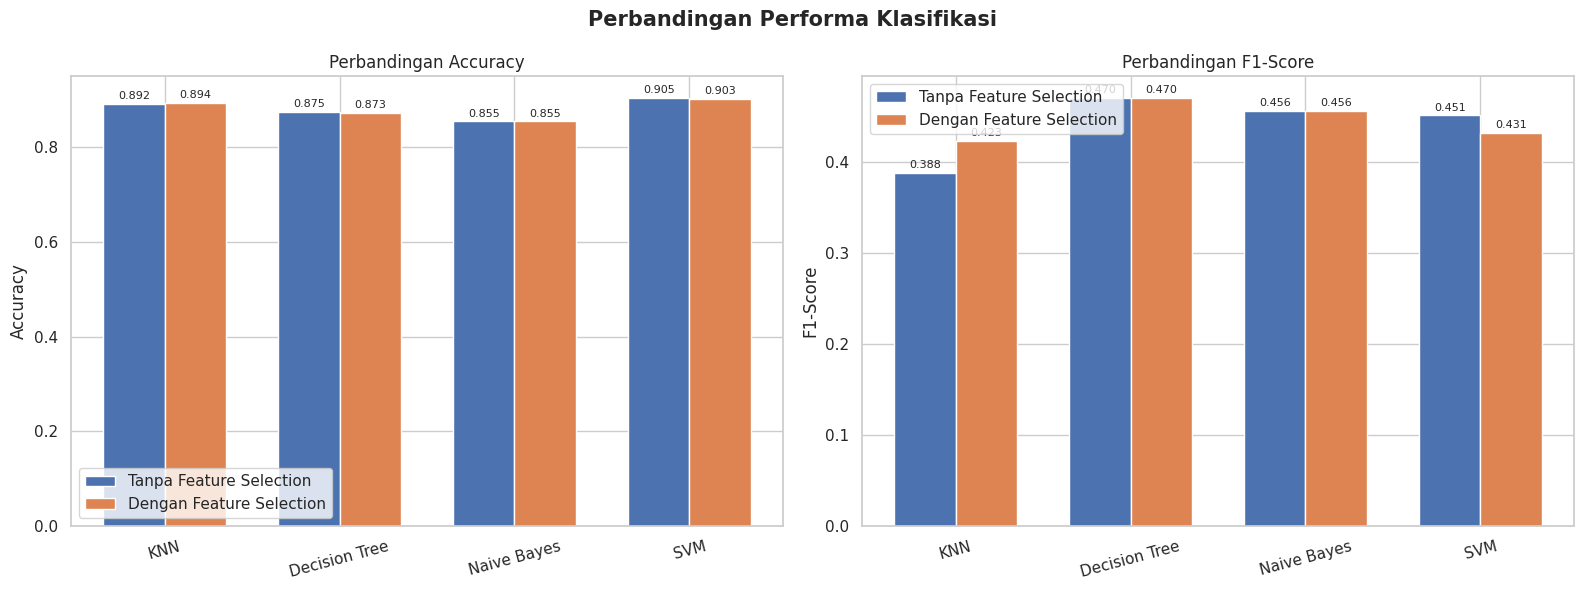


Membuat Confusion Matrix...


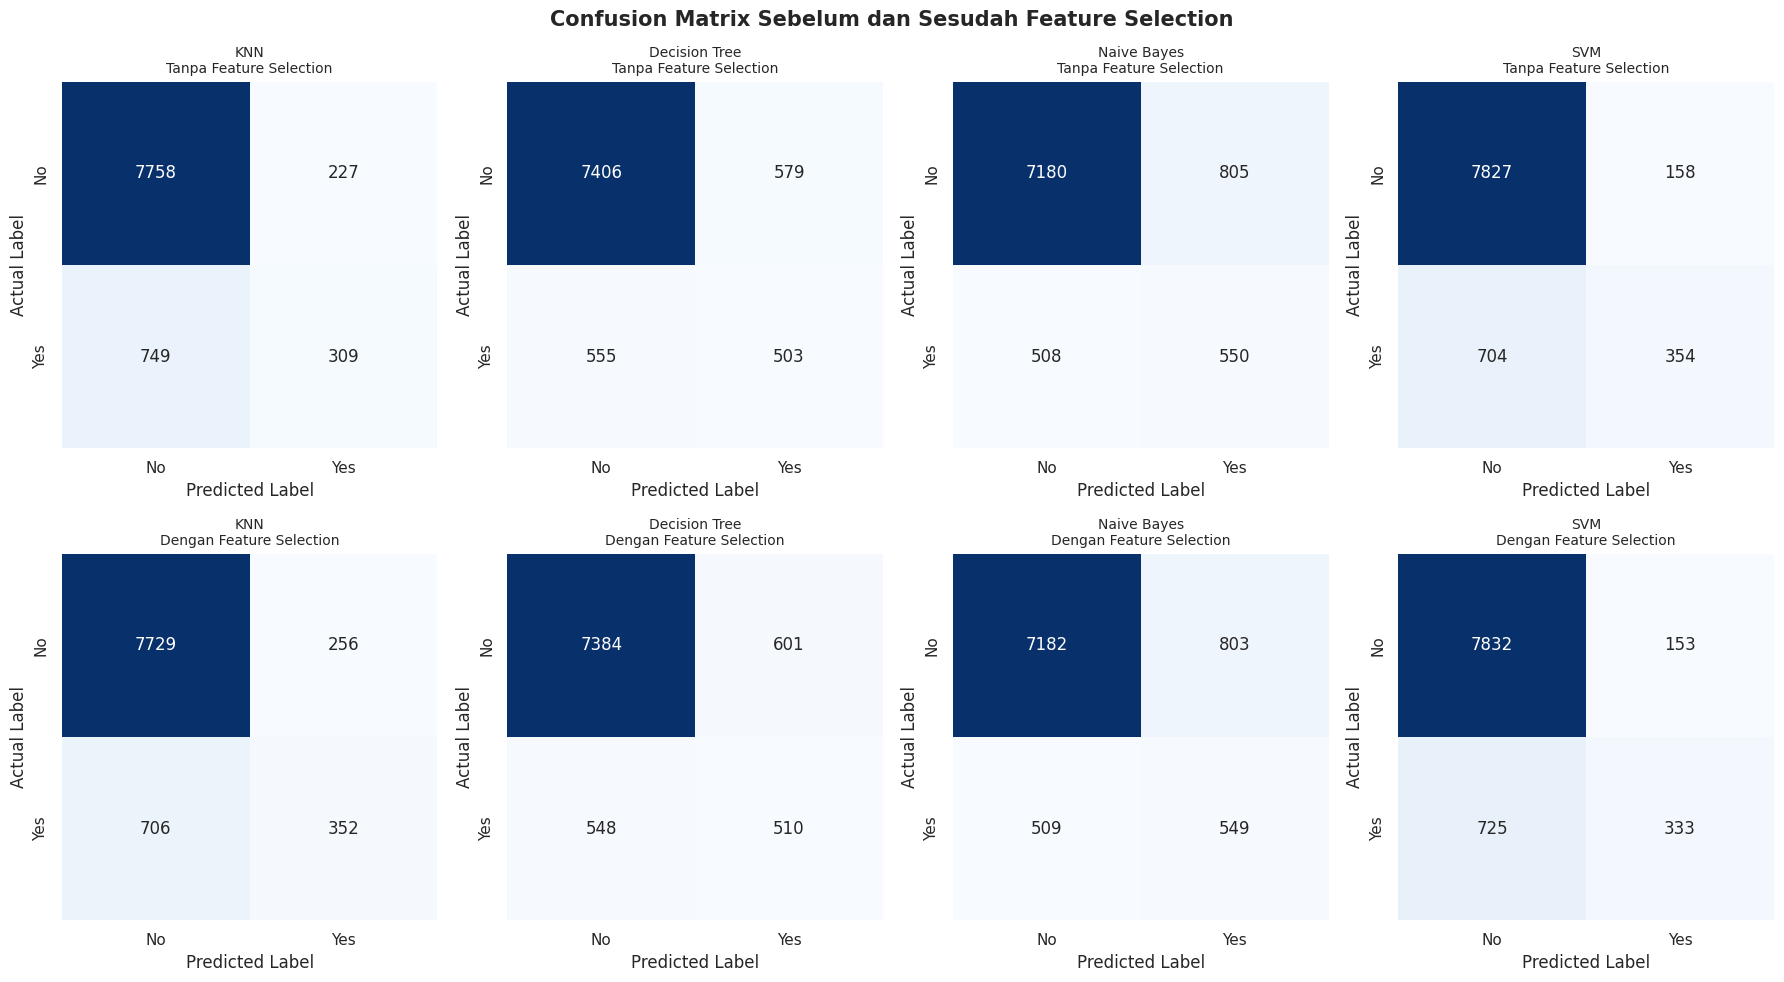


Membuat ROC Curve...


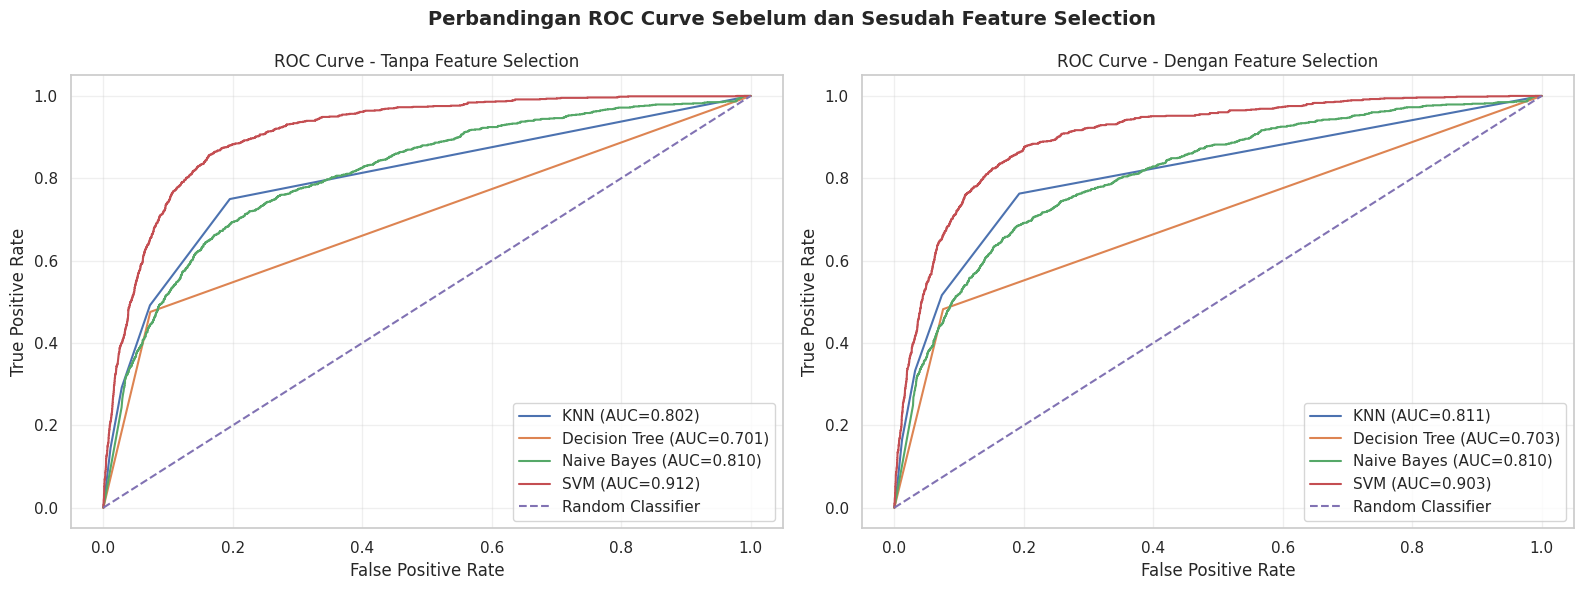


PERINGKAT MODEL TERBAIK


,Peringkat,Algoritma,Skenario,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Jumlah Fitur
0,1,Decision Tree,Dengan Feature Selection,0.8729,0.4590,0.4820,0.4703,0.7034,43
1,2,Decision Tree,Tanpa Feature Selection,0.8746,0.4649,0.4754,0.4701,0.7015,51
2,3,Naive Bayes,Tanpa Feature Selection,0.8548,0.4059,0.5198,0.4559,0.8101,51
3,4,Naive Bayes,Dengan Feature Selection,0.8549,0.4061,0.5189,0.4556,0.8100,43
4,5,SVM,Tanpa Feature Selection,0.9047,0.6914,0.3346,0.4510,0.9118,51
5,6,SVM,Dengan Feature Selection,0.9029,0.6852,0.3147,0.4313,0.9034,43
6,7,KNN,Dengan Feature Selection,0.8936,0.5789,0.3327,0.4226,0.8112,43
7,8,KNN,Tanpa Feature Selection,0.8921,0.5765,0.2921,0.3877,0.8021,51



MODEL TERBAIK BERDASARKAN F1-SCORE
------------------------------------------------------------
Algoritma          : Decision Tree
Skenario           : Dengan Feature Selection
Accuracy           : 0.8729
Precision          : 0.459
Recall             : 0.482
F1-Score           : 0.4703
ROC-AUC            : 0.7034
Jumlah Fitur       : 43

KESIMPULAN EKSPERIMEN


,Metrik,Rata-rata Sebelum FS,Rata-rata Sesudah FS,Perubahan (pp)
0,Accuracy,0.8815,0.8811,-0.0442
1,Precision,0.5347,0.5323,-0.2360
2,Recall,0.4055,0.4121,0.6616
3,F1-Score,0.4412,0.4449,0.3791
4,ROC-AUC,0.8064,0.8070,0.0626



Jumlah fitur berhasil direduksi dari 51 menjadi 43.
Secara rata-rata, penerapan Pearson Correlation meningkatkan F1-Score.

Eksperimen selesai!


In [ ]:
# ================================================================
# PENELITIAN: PERBANDINGAN ALGORITMA KLASIFIKASI DENGAN DAN TANPA
# PEARSON CORRELATION FEATURE SELECTION
#
# Dataset : bank-full.csv
# Algoritma: KNN, Decision Tree, Naive Bayes, SVM
# Evaluasi : Accuracy, Precision, Recall, F1-Score, ROC-AUC
# Validasi : Stratified Train-Test Split (80:20)
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score,
    ConfusionMatrixDisplay
)

from IPython.display import display

warnings.filterwarnings("ignore")

# ================================================================
# 1. KONFIGURASI PENELITIAN
# ================================================================

DATA_PATH = "/content/bank_data/bank-full.csv"

TEST_SIZE = 0.20
RANDOM_STATE = 42

# Ambang minimum korelasi absolut Pearson
CORR_THRESHOLD = 0.01

# ================================================================
# 2. MEMBACA DATASET
# ================================================================

print("=" * 75)
print("PENELITIAN KLASIFIKASI DENGAN PEARSON CORRELATION FEATURE SELECTION")
print("=" * 75)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, sep=";")

# Menghapus spasi pada nama kolom
df.columns = df.columns.str.strip()

# Menghapus duplikasi data
df = df.drop_duplicates().reset_index(drop=True)

TARGET = "y"

if TARGET not in df.columns:
    raise ValueError("Kolom target 'y' tidak ditemukan!")

print("\nDataset berhasil dimuat!")
print("Dimensi dataset:", df.shape)

# ================================================================
# 3. TABEL 1 - KARAKTERISTIK DATASET
# ================================================================

print("\n" + "=" * 75)
print("TABEL 1. KARAKTERISTIK DATASET")
print("=" * 75)

total_missing = df.isnull().sum().sum()

dataset_info = pd.DataFrame({
    "Karakteristik": [
        "Jumlah Instance",
        "Jumlah Fitur Awal",
        "Jumlah Kelas",
        "Missing Value",
        "Jumlah Data Training",
        "Jumlah Data Testing"
    ],
    "Nilai": [
        len(df),
        df.shape[1] - 1,
        df[TARGET].nunique(),
        total_missing,
        int(len(df) * (1 - TEST_SIZE)),
        len(df) - int(len(df) * (1 - TEST_SIZE))
    ]
})

display(dataset_info)

print("\nDistribusi Kelas:")

class_distribution = df[TARGET].value_counts().reset_index()
class_distribution.columns = ["Kelas", "Jumlah"]

class_distribution["Persentase (%)"] = (
    class_distribution["Jumlah"] / len(df) * 100
).round(2)

display(class_distribution)

# ================================================================
# 4. PEMISAHAN FITUR DAN TARGET
# ================================================================

X = df.drop(columns=[TARGET])
y = df[TARGET].map({"no": 0, "yes": 1})

if y.isnull().any():
    raise ValueError("Pastikan target hanya berisi kelas 'yes' dan 'no'!")

# Pembagian data sebelum feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

# ================================================================
# 5. PREPROCESSING DATA
# ================================================================

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["int64", "float64"]
).columns.tolist()

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit hanya menggunakan data training
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("\nJumlah fitur setelah preprocessing:",
      X_train_processed.shape[1])

# ================================================================
# 6. PERHITUNGAN PEARSON CORRELATION
# ================================================================

print("\n" + "=" * 75)
print("PERHITUNGAN PEARSON CORRELATION")
print("=" * 75)

# Korelasi dihitung hanya pada data training
correlation_data = X_train_processed.copy()
correlation_data["target"] = y_train

correlation_matrix = correlation_data.corr(method="pearson")

correlation_scores = correlation_matrix["target"].drop("target")

correlation_table = pd.DataFrame({
    "Fitur": correlation_scores.index,
    "Pearson Correlation": correlation_scores.values,
    "Absolute Correlation": correlation_scores.abs().values
})

correlation_table = correlation_table.sort_values(
    by="Absolute Correlation",
    ascending=False
).reset_index(drop=True)

# ================================================================
# TABEL 2 - HASIL ANALISIS KORELASI
# ================================================================

print("\n" + "=" * 75)
print("TABEL 2. HASIL ANALISIS KORELASI FITUR")
print("=" * 75)

display(correlation_table.round(5))

# ================================================================
# 7. FEATURE SELECTION
# ================================================================

selected_features = correlation_table.loc[
    correlation_table["Absolute Correlation"] >= CORR_THRESHOLD,
    "Fitur"
].tolist()

# Fallback jika tidak ada fitur yang melewati threshold
if len(selected_features) == 0:
    selected_features = (
        correlation_table.head(
            max(1, int(np.ceil(len(correlation_table) * 0.1)))
        )["Fitur"].tolist()
    )

# Menjamin tidak terjadi dataset tanpa fitur
if len(selected_features) == 0:
    raise ValueError("Feature Selection tidak menghasilkan fitur!")

removed_features = [
    feature for feature in feature_names
    if feature not in selected_features
]

# Dataset setelah seleksi
X_train_selected = X_train_processed[selected_features]
X_test_selected = X_test_processed[selected_features]

# ================================================================
# TABEL 3 - HASIL FEATURE SELECTION
# ================================================================

print("\n" + "=" * 75)
print("TABEL 3. HASIL FEATURE SELECTION")
print("=" * 75)

selection_table = correlation_table.copy()

selection_table["Status"] = selection_table["Fitur"].apply(
    lambda x: "Dipilih" if x in selected_features else "Dihapus"
)

selection_table["Ambang Korelasi"] = CORR_THRESHOLD

display(selection_table.round(5))

feature_summary = pd.DataFrame({
    "Keterangan": [
        "Jumlah fitur sebelum seleksi",
        "Jumlah fitur terpilih",
        "Jumlah fitur dihapus",
        "Persentase reduksi fitur"
    ],
    "Nilai": [
        len(feature_names),
        len(selected_features),
        len(removed_features),
        round(
            len(removed_features) / len(feature_names) * 100, 2
        )
    ]
})

print("\nRingkasan Feature Selection:")
display(feature_summary)

print("\nDaftar fitur terpilih:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

print("\nDaftar fitur yang dihapus:")
for i, feature in enumerate(removed_features, 1):
    print(f"{i}. {feature}")

# ================================================================
# 8. GRAFIK FLOWCHART METODOLOGI PENELITIAN
# ================================================================

print("\nMembuat Flowchart Metodologi Penelitian...")

fig, ax = plt.subplots(figsize=(10, 12))

ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

flow_steps = [
    "Dataset Bank Marketing",
    "Data Preprocessing",
    "Train-Test Split (80:20)",
    "Pearson Correlation Feature Selection",
    "Pemilihan Fitur Berdasarkan Threshold",
    "Klasifikasi: KNN, DT, NB, SVM",
    "Evaluasi Model",
    "Perbandingan Hasil Eksperimen"
]

positions = np.linspace(12.5, 1.5, len(flow_steps))

for i, (step, y_pos) in enumerate(zip(flow_steps, positions)):

    ax.text(
        5, y_pos, step,
        ha="center", va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor="lightblue",
            edgecolor="black"
        )
    )

    if i < len(flow_steps) - 1:
        ax.annotate(
            "",
            xy=(5, positions[i+1] + 0.45),
            xytext=(5, y_pos - 0.45),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title(
    "Flowchart Metodologi Penelitian",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 9. GRAFIK HEATMAP KORELASI FITUR
# ================================================================

print("\nMembuat Heatmap Korelasi...")

# Memilih maksimal 25 fitur dengan korelasi tertinggi
top_features = correlation_table.head(25)["Fitur"].tolist()

heatmap_data = X_train_processed[top_features].copy()
heatmap_data["Target"] = y_train

plt.figure(figsize=(16, 12))

sns.heatmap(
    heatmap_data.corr(method="pearson"),
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title(
    "Heatmap Pearson Correlation Antarfitur dan Target",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 10. KONFIGURASI ALGORITMA KLASIFIKASI
# ================================================================

models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=None,
        random_state=RANDOM_STATE
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=RANDOM_STATE
    )
}

# ================================================================
# TABEL 4 - KONFIGURASI ALGORITMA
# ================================================================

print("\n" + "=" * 75)
print("TABEL 4. KONFIGURASI ALGORITMA KLASIFIKASI")
print("=" * 75)

configuration_table = pd.DataFrame([
    {
        "Algoritma": "KNN",
        "Hyperparameter": "n_neighbors=5, weights=uniform",
        "Validasi": "Stratified Train-Test Split 80:20"
    },
    {
        "Algoritma": "Decision Tree",
        "Hyperparameter": "criterion=gini, max_depth=None",
        "Validasi": "Stratified Train-Test Split 80:20"
    },
    {
        "Algoritma": "Naive Bayes",
        "Hyperparameter": "GaussianNB default",
        "Validasi": "Stratified Train-Test Split 80:20"
    },
    {
        "Algoritma": "SVM",
        "Hyperparameter": "kernel=rbf, C=1.0, gamma=scale",
        "Validasi": "Stratified Train-Test Split 80:20"
    }
])

display(configuration_table)

# ================================================================
# 11. PELATIHAN DAN EVALUASI MODEL
# ================================================================

results = []
confusion_matrices = {}
roc_results = {}

scaler = StandardScaler()

# Standardisasi dihitung dari training data saja
X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

scaler_selected = StandardScaler()

X_train_selected_scaled = scaler_selected.fit_transform(
    X_train_selected
)

X_test_selected_scaled = scaler_selected.transform(
    X_test_selected
)

print("\n" + "=" * 75)
print("PROSES EKSPERIMEN KLASIFIKASI")
print("=" * 75)

for model_name, model in models.items():

    print(f"\nMenjalankan algoritma: {model_name}")

    for scenario in ["Tanpa Feature Selection", "Dengan Feature Selection"]:

        if scenario == "Tanpa Feature Selection":
            Xtr = X_train_scaled
            Xte = X_test_scaled
        else:
            Xtr = X_train_selected_scaled
            Xte = X_test_selected_scaled

        model_instance = model.__class__(**model.get_params())

        # Training
        model_instance.fit(Xtr, y_train)

        # Prediksi
        y_pred = model_instance.predict(Xte)

        # Probabilitas prediksi
        y_proba = model_instance.predict_proba(Xte)[:, 1]

        # Evaluasi
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        auc_score = roc_auc_score(y_test, y_proba)

        results.append({
            "Algoritma": model_name,
            "Skenario": scenario,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "ROC-AUC": auc_score,
            "Jumlah Fitur": Xtr.shape[1]
        })

        confusion_matrices[(model_name, scenario)] = confusion_matrix(
            y_test, y_pred
        )

        fpr, tpr, _ = roc_curve(y_test, y_proba)

        roc_results[(model_name, scenario)] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": auc_score
        }

        print(
            f"{scenario}: Accuracy={accuracy:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}, "
            f"F1={f1:.4f}, "
            f"AUC={auc_score:.4f}"
        )

results_df = pd.DataFrame(results)

# ================================================================
# 12. TABEL 5 - PERFORMA TANPA FEATURE SELECTION
# ================================================================

print("\n" + "=" * 75)
print("TABEL 5. PERFORMA KLASIFIKASI TANPA FEATURE SELECTION")
print("=" * 75)

baseline_table = results_df[
    results_df["Skenario"] == "Tanpa Feature Selection"
].copy()

baseline_table = baseline_table.drop(columns=["Skenario"])

display(
    baseline_table.round(4).reset_index(drop=True)
)

# ================================================================
# 13. TABEL 6 - PERFORMA DENGAN FEATURE SELECTION
# ================================================================

print("\n" + "=" * 75)
print("TABEL 6. PERFORMA KLASIFIKASI DENGAN FEATURE SELECTION")
print("=" * 75)

selected_table = results_df[
    results_df["Skenario"] == "Dengan Feature Selection"
].copy()

selected_table = selected_table.drop(columns=["Skenario"])

display(
    selected_table.round(4).reset_index(drop=True)
)

# ================================================================
# 14. TABEL 7 - PERBANDINGAN SEBELUM DAN SESUDAH FEATURE SELECTION
# ================================================================

print("\n" + "=" * 75)
print("TABEL 7. PERBANDINGAN PERFORMA SEBELUM DAN SESUDAH FS")
print("=" * 75)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison_rows = []

for algorithm in models.keys():

    before = results_df[
        (results_df["Algoritma"] == algorithm) &
        (results_df["Skenario"] == "Tanpa Feature Selection")
    ].iloc[0]

    after = results_df[
        (results_df["Algoritma"] == algorithm) &
        (results_df["Skenario"] == "Dengan Feature Selection")
    ].iloc[0]

    row = {"Algoritma": algorithm}

    for metric in metrics:

        row[f"{metric} Sebelum"] = before[metric]
        row[f"{metric} Sesudah"] = after[metric]

        # Perubahan dalam poin persentase
        row[f"Delta {metric} (pp)"] = (
            after[metric] - before[metric]
        ) * 100

    row["Fitur Sebelum"] = before["Jumlah Fitur"]
    row["Fitur Sesudah"] = after["Jumlah Fitur"]

    row["Reduksi Fitur (%)"] = (
        (before["Jumlah Fitur"] - after["Jumlah Fitur"])
        / before["Jumlah Fitur"] * 100
    )

    comparison_rows.append(row)

comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(4))

# ================================================================
# 15. GRAFIK JUMLAH FITUR SEBELUM DAN SESUDAH SELEKSI
# ================================================================

print("\nMembuat Grafik Jumlah Fitur...")

plt.figure(figsize=(9, 6))

feature_counts = [
    len(feature_names),
    len(selected_features)
]

bars = plt.bar(
    ["Sebelum Feature Selection", "Sesudah Feature Selection"],
    feature_counts
)

plt.bar_label(bars, fmt="%.0f", padding=3)

plt.ylabel("Jumlah Fitur")
plt.title(
    "Perbandingan Jumlah Fitur Sebelum dan Sesudah Seleksi",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 16. GROUPED BAR CHART ACCURACY DAN F1-SCORE
# ================================================================

print("\nMembuat Grafik Perbandingan Accuracy dan F1-Score...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

algorithm_names = list(models.keys())
x = np.arange(len(algorithm_names))
width = 0.35

for ax, metric in zip(axes, ["Accuracy", "F1-Score"]):

    before_values = [
        results_df[
            (results_df["Algoritma"] == name) &
            (results_df["Skenario"] == "Tanpa Feature Selection")
        ][metric].values[0]
        for name in algorithm_names
    ]

    after_values = [
        results_df[
            (results_df["Algoritma"] == name) &
            (results_df["Skenario"] == "Dengan Feature Selection")
        ][metric].values[0]
        for name in algorithm_names
    ]

    bars1 = ax.bar(
        x - width / 2,
        before_values,
        width,
        label="Tanpa Feature Selection"
    )

    bars2 = ax.bar(
        x + width / 2,
        after_values,
        width,
        label="Dengan Feature Selection"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(algorithm_names, rotation=15)
    ax.set_ylabel(metric)
    ax.set_title(f"Perbandingan {metric}")
    ax.legend()
    ax.bar_label(bars1, fmt="%.3f", fontsize=8, padding=2)
    ax.bar_label(bars2, fmt="%.3f", fontsize=8, padding=2)

plt.suptitle(
    "Perbandingan Performa Klasifikasi",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 17. CONFUSION MATRIX SELURUH MODEL
# ================================================================

print("\nMembuat Confusion Matrix...")

fig, axes = plt.subplots(2, 4, figsize=(18, 10))

scenarios = [
    "Tanpa Feature Selection",
    "Dengan Feature Selection"
]

for row_idx, scenario in enumerate(scenarios):

    for col_idx, algorithm in enumerate(models.keys()):

        ax = axes[row_idx, col_idx]

        cm = confusion_matrices[(algorithm, scenario)]

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["No", "Yes"],
            yticklabels=["No", "Yes"],
            ax=ax
        )

        ax.set_title(
            f"{algorithm}\n{scenario}",
            fontsize=10
        )

        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrix Sebelum dan Sesudah Feature Selection",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 18. ROC CURVE DAN AUC
# ================================================================

print("\nMembuat ROC Curve...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, scenario in zip(axes, scenarios):

    for algorithm in models.keys():

        roc_data = roc_results[(algorithm, scenario)]

        ax.plot(
            roc_data["fpr"],
            roc_data["tpr"],
            label=f"{algorithm} (AUC={roc_data['auc']:.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_title(f"ROC Curve - {scenario}")

    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Perbandingan ROC Curve Sebelum dan Sesudah Feature Selection",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ================================================================
# 19. PERINGKAT MODEL TERBAIK
# ================================================================

print("\n" + "=" * 75)
print("PERINGKAT MODEL TERBAIK")
print("=" * 75)

ranking = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

ranking.insert(0, "Peringkat", ranking.index + 1)

display(ranking.round(4))

best_model = ranking.iloc[0]

print("\nMODEL TERBAIK BERDASARKAN F1-SCORE")
print("-" * 60)
print("Algoritma          :", best_model["Algoritma"])
print("Skenario           :", best_model["Skenario"])
print("Accuracy           :", round(best_model["Accuracy"], 4))
print("Precision          :", round(best_model["Precision"], 4))
print("Recall             :", round(best_model["Recall"], 4))
print("F1-Score           :", round(best_model["F1-Score"], 4))
print("ROC-AUC            :", round(best_model["ROC-AUC"], 4))
print("Jumlah Fitur       :", int(best_model["Jumlah Fitur"]))

# ================================================================
# 20. KESIMPULAN OTOMATIS
# ================================================================

print("\n" + "=" * 75)
print("KESIMPULAN EKSPERIMEN")
print("=" * 75)

avg_before = results_df[
    results_df["Skenario"] == "Tanpa Feature Selection"
][metrics].mean()

avg_after = results_df[
    results_df["Skenario"] == "Dengan Feature Selection"
][metrics].mean()

summary = pd.DataFrame({
    "Metrik": metrics,
    "Rata-rata Sebelum FS": avg_before.values,
    "Rata-rata Sesudah FS": avg_after.values,
    "Perubahan (pp)": (
        avg_after.values - avg_before.values
    ) * 100
})

display(summary.round(4))

print(
    f"\nJumlah fitur berhasil direduksi dari "
    f"{len(feature_names)} menjadi {len(selected_features)}."
)

if avg_after["F1-Score"] > avg_before["F1-Score"]:
    print(
        "Secara rata-rata, penerapan Pearson Correlation "
        "meningkatkan F1-Score."
    )
elif avg_after["F1-Score"] < avg_before["F1-Score"]:
    print(
        "Secara rata-rata, penerapan Pearson Correlation "
        "menurunkan F1-Score."
    )
else:
    print(
        "Secara rata-rata, F1-Score tidak mengalami perubahan."
    )

print("\nEksperimen selesai!")
print("=" * 75)

```markdown
## Analisis Tambahan: 5-Fold Cross-Validation

Untuk memastikan performa model stabil dan tidak bergantung pada satu pembagian *train-test split* saja, kita akan melakukan evaluasi menggunakan **Stratified 5-Fold Cross-Validation**. Analisis ini membandingkan kinerja model tanpa dan dengan *Pearson Correlation Feature Selection*.
```

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

print("=" * 75)
print("PROSES EVALUASI DENGAN 5-FOLD CROSS-VALIDATION PADA SELURUH DATA")
print("=" * 75)

# Definisikan model kembali untuk memastikan kondisi awal bersih
cv_models = {
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski"),
    "Decision Tree": DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", probability=False, random_state=RANDOM_STATE) # probability=False tetap digunakan agar proses SVM tidak stuck berjam-jam
}

# Gunakan StratifiedKFold agar distribusi kelas tetap seimbang di setiap fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring_metrics = ['accuracy', 'precision', 'recall', 'f1']
cv_results_list = []

for model_name, model in cv_models.items():
    print(f"\nMelakukan Cross-Validation untuk: {model_name}...")

    for scenario, data_input in [("Tanpa Feature Selection", X_all_scaled),
                                 ("Dengan Feature Selection", X_all_selected_scaled)]:

        cv_scores = cross_validate(
            model,
            data_input,
            y,
            cv=cv,
            scoring=scoring_metrics,
            n_jobs=-1
        )

        cv_results_list.append({
            "Algoritma": model_name,
            "Skenario": scenario,
            "Jumlah Fitur": data_input.shape[1],
            "Accuracy (Mean)": np.mean(cv_scores['test_accuracy']),
            "Accuracy (Std)": np.std(cv_scores['test_accuracy']),
            "Precision (Mean)": np.mean(cv_scores['test_precision']),
            "Precision (Std)": np.std(cv_scores['test_precision']),
            "Recall (Mean)": np.mean(cv_scores['test_recall']),
            "Recall (Std)": np.std(cv_scores['test_recall']),
            "F1-Score (Mean)": np.mean(cv_scores['test_f1']),
            "F1-Score (Std)": np.std(cv_scores['test_f1'])
        })

cv_results_df = pd.DataFrame(cv_results_list)

# ================================================================
# MENAMPILKAN TABEL HASIL CROSS-VALIDATION
# ================================================================

print("\n" + "=" * 75)
print("TABEL EVALUASI CROSS-VALIDATION (SEBELUM VS SESUDAH FEATURE SELECTION)")
print("=" * 75)

display(cv_results_df.round(4))

PROSES EVALUASI DENGAN 5-FOLD CROSS-VALIDATION PADA SELURUH DATA

Melakukan Cross-Validation untuk: KNN...

Melakukan Cross-Validation untuk: Decision Tree...

Melakukan Cross-Validation untuk: Naive Bayes...

Melakukan Cross-Validation untuk: SVM...

TABEL EVALUASI CROSS-VALIDATION (SEBELUM VS SESUDAH FEATURE SELECTION)


,Algoritma,Skenario,Jumlah Fitur,Accuracy (Mean),Accuracy (Std),Precision (Mean),Precision (Std),Recall (Mean),Recall (Std),F1-Score (Mean),F1-Score (Std)
0,KNN,Tanpa Feature Selection,51,0.8924,0.0021,0.5735,0.0169,0.3135,0.0151,0.4052,0.0147
1,KNN,Dengan Feature Selection,43,0.8922,0.0019,0.5668,0.0151,0.3348,0.0154,0.4207,0.0129
2,Decision Tree,Tanpa Feature Selection,51,0.8751,0.0023,0.4671,0.0096,0.4806,0.0123,0.4737,0.0100
3,Decision Tree,Dengan Feature Selection,43,0.8751,0.0031,0.4675,0.0126,0.4808,0.0152,0.4739,0.0115
4,Naive Bayes,Tanpa Feature Selection,51,0.8503,0.0027,0.3923,0.0074,0.5090,0.0118,0.4430,0.0078
5,Naive Bayes,Dengan Feature Selection,43,0.8519,0.0026,0.3967,0.0074,0.5111,0.0118,0.4466,0.0079
6,SVM,Tanpa Feature Selection,51,0.9025,0.0018,0.6667,0.0250,0.3354,0.0114,0.4459,0.0075
7,SVM,Dengan Feature Selection,43,0.9024,0.0021,0.6687,0.0272,0.3314,0.0110,0.4428,0.0082
